# Лабораторна робота № 9 — класифікація Food-101 за допомогою CNN

**Номер у списку:** 17. **Індекси класів у `meta/classes.txt`:** 16, 46, 76 (від нуля): `cheese_plate`, `garlic_bread`, `pizza`. **Мета:** побудувати власну CNN для трьох взаємовиключних страв, порівняти базову модель і Dropout 0.3 на validation та оцінити обрану конфігурацію на незалежному test.

**Порядок:** виконуйте клітинки згори вниз. Повний Food-101 повинен бути розпакований у папці з `images/` і `meta/`. Змінити потрібно лише `FOOD_ROOT` у кроці 1; за бажанням — `OWN_PHOTO` у кроці 12. Фактичні метрики й висновки нижче обчислюються під час запуску, без попередньо підставлених значень.

## Крок 1. Середовище, шляхи та відтворюваність

Фіксуємо версії, seed і доступне обладнання. У проєкті вже є сумісне середовище `Lab5/.venv` з Python 3.9 і TensorFlow 2.16.2. Оберіть його як Jupyter-ядро; нового `.venv` створювати не потрібно. Дані за замовчуванням шукаються в `Lab9/datasets/food-101`; можна задати `FOOD_ROOT` у середовищі або змінити значення в клітинці.

In [1]:
import json
import os
import platform
import random
import shutil
import sys
import time
from collections import Counter
from hashlib import sha256
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, UnidentifiedImageError
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
                             classification_report, f1_score)
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
N = 17
IMAGE_SIZE = (128, 128)
BATCH_SIZE = 32
EPOCHS = 30
keras.utils.set_random_seed(SEED)

# Працює і коли Jupyter відкрито з кореня репозиторію, і з папки Lab9.
LAB_DIR = Path.cwd() / "Lab9" if (Path.cwd() / "Lab9" / "Lab9.ipynb").is_file() else Path.cwd()
LAB_DIR = LAB_DIR.resolve()
FOOD_ROOT = Path(os.environ.get("FOOD_ROOT", str(LAB_DIR / "datasets" / "food-101"))).expanduser().resolve()
DATA_ROOT = LAB_DIR / "data" / "food101_lab9"
RESULTS = LAB_DIR / "results"
RESULTS.mkdir(exist_ok=True)

print("Python:", sys.version.split()[0], "| TensorFlow:", tf.__version__)
print("ОС:", platform.platform(), "| Пристрої:", tf.config.list_physical_devices())
print("Seed:", SEED, "| FOOD_ROOT:", FOOD_ROOT)
assert 1 <= N <= 41
for rel in ("images", "meta/classes.txt", "meta/train.txt", "meta/test.txt"):
    assert (FOOD_ROOT / rel).exists(), f"Відсутній {FOOD_ROOT / rel}. Укажіть FOOD_ROOT у кроці 1."

Python: 3.9.6 | TensorFlow: 2.16.2
ОС: macOS-14.8.5-x86_64-i386-64bit | Пристрої: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]
Seed: 42 | FOOD_ROOT: /Users/staslulko/Documents/GitHub/data-mining/Lab9/datasets/food-101


Matplotlib is building the font cache; this may take a moment.
/Users/staslulko/Documents/GitHub/data-mining/Lab5/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


## Крок 2. Визначення класів і початкових списків

Індекси Food-101 відрізняються від цілочисельних міток моделі. `CLASS_NAMES[0]`, `[1]`, `[2]` відповідають softmax-виходам 0, 1, 2. Зберігаємо лише офіційні записи трьох класів.

In [2]:
all_classes = sorted((FOOD_ROOT / "meta/classes.txt").read_text(encoding="utf-8").splitlines())
assert len(all_classes) == 101 and len(set(all_classes)) == 101
indices = [N - 1, N + 29, N + 59]
CLASS_NAMES = [all_classes[i] for i in indices]
print("Індекси Food-101 і класи:", list(zip(indices, CLASS_NAMES)))
print("Мітки CNN:", dict(enumerate(CLASS_NAMES)))

def read_meta(part):
    ids = (FOOD_ROOT / "meta" / f"{part}.txt").read_text(encoding="utf-8").splitlines()
    ids = [x.strip() for x in ids if x.strip() and x.split("/", 1)[0] in CLASS_NAMES]
    assert len(ids) == len(set(ids)), f"Повторні ID у meta/{part}.txt"
    return ids

source_train, source_test = read_meta("train"), read_meta("test")
for name in CLASS_NAMES:
    assert sum(x.startswith(name + "/") for x in source_train) == 750
    assert sum(x.startswith(name + "/") for x in source_test) == 250
assert set(source_train).isdisjoint(source_test)
print("Офіційні записи:", len(source_train), "train;", len(source_test), "test")

Індекси Food-101 і класи: [(16, 'cheese_plate'), (46, 'garlic_bread'), (76, 'pizza')]
Мітки CNN: {0: 'cheese_plate', 1: 'garlic_bread', 2: 'pizza'}
Офіційні записи: 2250 train; 750 test


## Крок 3. Стратифікований поділ, маніфест і перевірка файлів

Окремо перемішуємо 750 офіційних train-ID кожного класу: 150 у validation, 600 у train. Офіційний test не бере участі в навчанні та виборі конфігурації. При повторному запуску наявний каталог звіряється з очікуваними файлами; код нічого автоматично не видаляє. Перевіряємо SHA-256 між усіма частинами й декодування кожного JPEG. Схожі, але змінені копії SHA-256 не виявляє.

In [3]:
rng = np.random.default_rng(SEED)
split_ids = {"train": [], "val": [], "test": source_test.copy()}
for name in CLASS_NAMES:
    class_ids = np.array([x for x in source_train if x.startswith(name + "/")])
    rng.shuffle(class_ids)
    split_ids["val"].extend(class_ids[:150].tolist())
    split_ids["train"].extend(class_ids[150:].tolist())
for part in split_ids:
    split_ids[part].sort()
expected_counts = {"train": 600, "val": 150, "test": 250}
for part, ids in split_ids.items():
    assert len(ids) == 3 * expected_counts[part]
    assert all(sum(x.startswith(name + "/") for x in ids) == expected_counts[part]
               for name in CLASS_NAMES)
assert not (set(split_ids["train"]) & set(split_ids["val"]))
assert not (set(split_ids["train"]) & set(split_ids["test"]))
assert not (set(split_ids["val"]) & set(split_ids["test"]))

for part, ids in split_ids.items():
    part_dir = DATA_ROOT / part
    expected = {f"{item}.jpg" for item in ids}
    if part_dir.exists():
        actual = {p.relative_to(part_dir).as_posix() for p in part_dir.rglob("*") if p.is_file()}
        unexpected = actual - expected
        if unexpected:
            print(part, "зайві файли:", sorted(unexpected)[:10])
            raise RuntimeError("Каталог містить зайві файли; перевірте їх вручну.")
    for name in CLASS_NAMES:
        (part_dir / name).mkdir(parents=True, exist_ok=True)
    for item in ids:
        source = FOOD_ROOT / "images" / f"{item}.jpg"
        dest = part_dir / f"{item}.jpg"
        if not source.is_file():
            raise FileNotFoundError(source)
        if not dest.exists():
            shutil.copy2(source, dest)
    actual = {p.relative_to(part_dir).as_posix() for p in part_dir.rglob("*") if p.is_file()}
    assert actual == expected, f"Різниця {part}: missing={sorted(expected-actual)[:10]}, extra={sorted(actual-expected)[:10]}"

hash_owner = {}
for part, ids in split_ids.items():
    for item in ids:
        path = DATA_ROOT / part / f"{item}.jpg"
        digest = sha256(path.read_bytes()).hexdigest()
        source_digest = sha256((FOOD_ROOT / "images" / f"{item}.jpg").read_bytes()).hexdigest()
        assert digest == source_digest, f"Копія відрізняється від джерела: {path}"
        if digest in hash_owner and hash_owner[digest][0] != part:
            raise AssertionError(f"Точний дублікат між частинами: {hash_owner[digest]} і {(part, item)}")
        hash_owner[digest] = (part, item)
        try:
            with Image.open(path) as img:
                img.verify()
            with Image.open(path) as img:
                img.convert("RGB").load()
        except (UnidentifiedImageError, OSError) as exc:
            raise RuntimeError(f"Не читається {path}") from exc

manifest = {"seed": SEED, "student_number": N, "class_indices": indices,
            "class_names": CLASS_NAMES, "source": "official Food-101 train.txt/test.txt",
            "splits": {part: [f"{item}.jpg" for item in ids]
                       for part, ids in split_ids.items()},
            "counts_per_class": expected_counts}
(LAB_DIR / "manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
print(pd.DataFrame({part: {name: sum(x.startswith(name + "/") for x in ids)
                           for name in CLASS_NAMES} for part, ids in split_ids.items()}))
print("Усі 3000 зображень читаються; перетинів ID та SHA-256 між частинами немає.")

              train  val  test
cheese_plate    600  150   250
garlic_bread    600  150   250
pizza           600  150   250
Усі 3000 зображень читаються; перетинів ID та SHA-256 між частинами немає.


## Крок 4. Огляд зображень і якості міток

По п'ять **train** зображень кожного класу дають змогу помітити шум міток, незвичний ракурс, фон та візуально близькі кадри. Це огляд, а не автоматичне очищення. Якщо потрібне вилучення, його слід узгодити й повторно створити маніфест із фактичними кількостями.

**Огляд отриманого Food-101:** у 15 train-зразках `cheese_plate` сир іноді займає малу частину кадру, а на фото `garlic_bread` хліб трапляється разом з іншими продуктами. Фото `pizza` різняться масштабом і освітленням. Явно неправильної мітки або майже однакової пари серед цих 15 прикладів не встановлено; цей огляд не виключає шуму чи близьких дублікатів в інших файлах.

Lab9.ipynb cell 9:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


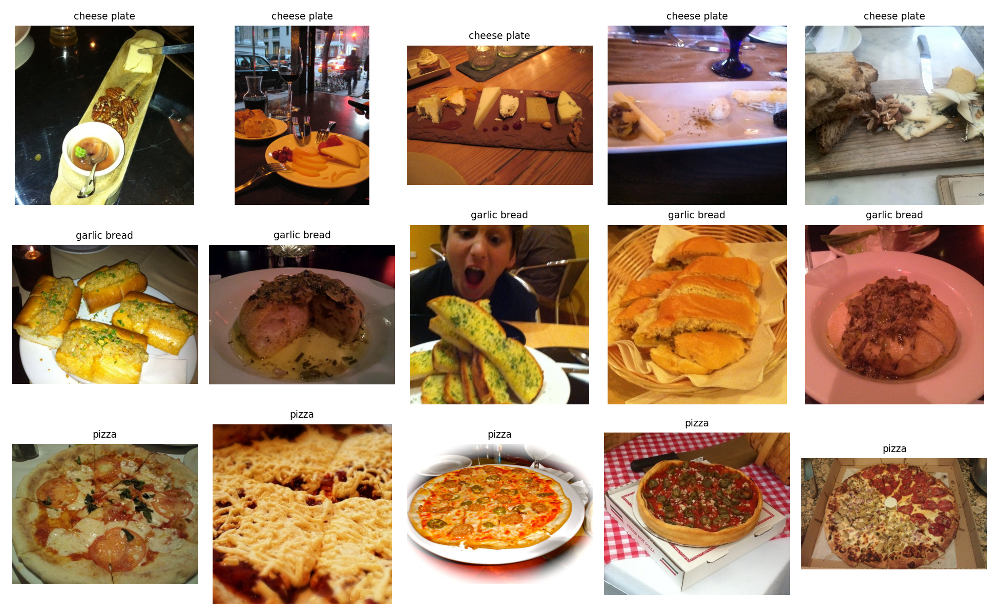

In [4]:
fig, axes = plt.subplots(len(CLASS_NAMES), 5, figsize=(13, 8))
for row, name in enumerate(CLASS_NAMES):
    examples = [x for x in split_ids["train"] if x.startswith(name + "/")][:5]
    for col, item in enumerate(examples):
        with Image.open(DATA_ROOT / "train" / f"{item}.jpg") as im:
            axes[row, col].imshow(im.convert("RGB"))
        axes[row, col].set_title(name.replace("_", " "), fontsize=9)
        axes[row, col].axis("off")
plt.tight_layout()
plt.savefig(RESULTS / "data_samples.png", dpi=150)
plt.show()

## Крок 5. Ручний розрахунок згортки

Для `stride=1`, `valid`, нульового bias: верхня ліва позиція дорівнює `1·1 + 2·0 + 0·0 + 1·(−1) = 0`. Усі чотири значення: `[[0, −1], [−2, 0]]`. Після `bias=1` і ReLU: `[[1, 0], [0, 1]]`. Те саме ядро застосовується в кожній позиції, тому число параметрів не залежить від ширини й висоти входу. Це локальна сума поелементних добутків, а не звичайне матричне множення; `Conv2D` обчислює взаємну кореляцію без перевертання ядра.

In [5]:
X = np.array([[1, 2, 0], [0, 1, 3], [2, 2, 1]], dtype=np.float32)
K = np.array([[1, 0], [0, -1]], dtype=np.float32)
manual = np.array([[np.sum(X[i:i+2, j:j+2] * K) for j in range(2)] for i in range(2)])
after_relu = np.maximum(manual + 1, 0)
tf_result = tf.nn.conv2d(X[None, :, :, None], K[:, :, None, None], strides=1, padding="VALID").numpy()[0, :, :, 0]
print("Без bias:", manual, "З bias=1 і ReLU:", after_relu, sep="\n")
np.testing.assert_array_equal(manual, [[0, -1], [-2, 0]])
np.testing.assert_array_equal(after_relu, [[1, 0], [0, 1]])
np.testing.assert_allclose(tf_result, manual)

Без bias:
[[ 0. -1.]
 [-2.  0.]]
З bias=1 і ReLU:
[[1. 0.]
 [0. 1.]]


## Крок 6. Батчі й форми тензорів

RGB-образ має форму `(128, 128, 3)`, батч — `(B, 128, 128, 3)`, мітки — `(B,)` зі значеннями 0–2. Resize змінює геометрію та не нормалізує пікселі; `Rescaling` є в самій моделі. `cache()` не застосовується, щоб не зайняти зайву пам'ять. Для validation/test `shuffle=False`, щоб мітки й прогнози збігалися за порядком.

In [6]:
def load_split(part, training=False):
    ds = keras.utils.image_dataset_from_directory(
        DATA_ROOT / part, class_names=CLASS_NAMES, label_mode="int",
        color_mode="rgb", image_size=IMAGE_SIZE, batch_size=BATCH_SIZE,
        shuffle=training, seed=SEED)
    options = tf.data.Options()
    options.experimental_deterministic = True
    return ds.with_options(options).prefetch(tf.data.AUTOTUNE)

train_ds = load_split("train", True)
val_ds = load_split("val")
images, labels = next(iter(train_ds))
print("Зображення:", images.shape, "мітки:", labels.shape)
print("Діапазон:", float(tf.reduce_min(images)), float(tf.reduce_max(images)))
assert images.shape[1:] == (128, 128, 3) and labels.ndim == 1
assert set(np.unique(labels.numpy())).issubset({0, 1, 2})

Found 1800 files belonging to 3 classes.
Found 450 files belonging to 3 classes.
Зображення: (32, 128, 128, 3) мітки: (32,)
Діапазон: 0.0 255.0


## Крок 7. Архітектура базової CNN

Три фільтри `3×3` для RGB мають 27 ваг кожен плюс bias. Кількість фільтрів задає число вихідних карт. `same` зберігає просторову форму після Conv; `MaxPooling2D(2)` щоразу ділить її навпіл. ReLU додає нелінійність. GAP усереднює кожну карту і дає 64 числа; Flatten дав би `16×16×64=16384` чисел перед Dense та значно більше параметрів. MaxPooling може втрачати корисні дрібні деталі.

Параметри: Conv16 `(3·3·3+1)·16=448`; Conv32 `4640`; Conv64 `18496`; Dense `(64+1)·3=195`; разом **23779**. Після pool форми: `64×64×16`, `32×32×32`, `16×16×64`. Три взаємовиключні класи представлені цілими мітками, softmax і `SparseCategoricalCrossentropy`.

In [7]:
def make_model(dropout=0.0):
    inputs = keras.Input(shape=(128, 128, 3))
    x = layers.Rescaling(1.0 / 255)(inputs)
    for i, filters in enumerate((16, 32, 64), 1):
        x = layers.Conv2D(filters, 3, padding="same", activation="relu", name=f"conv{i}")(x)
        x = layers.MaxPooling2D(2)(x)
    x = layers.GlobalAveragePooling2D()(x)
    if dropout > 0:
        x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(3, activation="softmax")(x)
    model = keras.Model(inputs, outputs)
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss=keras.losses.SparseCategoricalCrossentropy(),
                  metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")])
    return model

keras.utils.set_random_seed(SEED)
model = make_model()
model.summary()
assert model.count_params() == 23779

Model: "functional"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼─────────────────────

## Крок 8. Базове навчання

Правило однакове для обох дослідів: максимум 30 епох, `EarlyStopping` за `val_loss`, patience 5 і відновлення найкращих ваг. Фіксуємо число епох, найкращу епоху, час і обидві validation-метрики. `val_accuracy > train_accuracy` саме по собі не означає недонавчання.

Found 1800 files belonging to 3 classes.
Epoch 1/30
57/57 - 11s - 187ms/step - accuracy: 0.4111 - loss: 1.0715 - val_accuracy: 0.5133 - val_loss: 1.0133
Epoch 2/30
57/57 - 10s - 169ms/step - accuracy: 0.5022 - loss: 1.0057 - val_accuracy: 0.5489 - val_loss: 0.9515
Epoch 3/30
57/57 - 11s - 190ms/step - accuracy: 0.5717 - loss: 0.9250 - val_accuracy: 0.5022 - val_loss: 0.9752
Epoch 4/30
57/57 - 10s - 180ms/step - accuracy: 0.5656 - loss: 0.9207 - val_accuracy: 0.5200 - val_loss: 0.9607
Epoch 5/30
57/57 - 10s - 176ms/step - accuracy: 0.6178 - loss: 0.8792 - val_accuracy: 0.6022 - val_loss: 0.8716
Epoch 6/30
57/57 - 11s - 194ms/step - accuracy: 0.6033 - loss: 0.8872 - val_accuracy: 0.6289 - val_loss: 0.8606
Epoch 7/30
57/57 - 12s - 211ms/step - accuracy: 0.6294 - loss: 0.8647 - val_accuracy: 0.5689 - val_loss: 0.8930
Epoch 8/30
57/57 - 12s - 210ms/step - accuracy: 0.6250 - loss: 0.8571 - val_accuracy: 0.5111 - val_loss: 1.0159
Epoch 9/30
57/57 - 11s - 194ms/step - accuracy: 0.6217 - loss: 

Lab9.ipynb cell 17:28: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


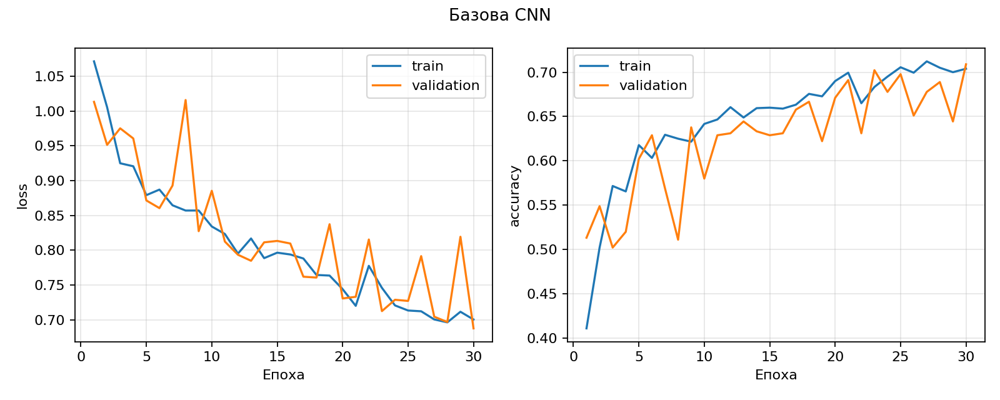

In [8]:
def fit_model(model, name):
    keras.utils.set_random_seed(SEED)
    current_train = load_split("train", True)  # однаковий початковий порядок батчів
    start = time.perf_counter()
    history = model.fit(current_train, validation_data=val_ds, epochs=EPOCHS,
        callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                                  restore_best_weights=True)], verbose=2)
    seconds = time.perf_counter() - start
    val = model.evaluate(val_ds, verbose=0, return_dict=True)
    record = {"model": name, "dropout": 0.3 if name == "dropout_03" else 0.0,
              "params": model.count_params(), "epochs": len(history.history["loss"]),
              "best_epoch": int(np.argmin(history.history["val_loss"]) + 1),
              "seconds": round(seconds, 2), "val_loss": float(val["loss"]),
              "val_accuracy": float(val["accuracy"])}
    return history, record

def plot_history(history, title, filename):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    epoch_axis = range(1, len(history.history["loss"]) + 1)
    for ax, metric in zip(axes, ("loss", "accuracy")):
        ax.plot(epoch_axis, history.history[metric], label="train")
        ax.plot(epoch_axis, history.history["val_" + metric], label="validation")
        ax.set(xlabel="Епоха", ylabel=metric)
        ax.legend(); ax.grid(alpha=0.3)
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(RESULTS / filename, dpi=160)
    plt.show()

base_history, base_record = fit_model(model, "baseline")
plot_history(base_history, "Базова CNN", "baseline_curves.png")
print(base_record)

## Крок 9. Контрольований експеримент і вибір

**Гіпотеза:** Dropout 0.3 після GAP може знизити перенавчання і validation loss. Міняємо лише цей чинник; дані, optimizer, seed, максимум епох і EarlyStopping однакові. Вибір робимо за мінімальним `val_loss`, за рівності лишаємо базову модель. Різні пристрої можуть дати трохи різні результати навіть із seed 42.

Found 1800 files belonging to 3 classes.
Epoch 1/30
57/57 - 11s - 201ms/step - accuracy: 0.4178 - loss: 1.0710 - val_accuracy: 0.5222 - val_loss: 1.0115
Epoch 2/30
57/57 - 10s - 179ms/step - accuracy: 0.5178 - loss: 1.0015 - val_accuracy: 0.5867 - val_loss: 0.9295
Epoch 3/30
57/57 - 10s - 181ms/step - accuracy: 0.5906 - loss: 0.9269 - val_accuracy: 0.5067 - val_loss: 0.9440
Epoch 4/30
57/57 - 10s - 178ms/step - accuracy: 0.5767 - loss: 0.9191 - val_accuracy: 0.6044 - val_loss: 0.8809
Epoch 5/30
57/57 - 10s - 178ms/step - accuracy: 0.6083 - loss: 0.8822 - val_accuracy: 0.6356 - val_loss: 0.8551
Epoch 6/30
57/57 - 10s - 178ms/step - accuracy: 0.6011 - loss: 0.9011 - val_accuracy: 0.6200 - val_loss: 0.8641
Epoch 7/30
57/57 - 10s - 179ms/step - accuracy: 0.6206 - loss: 0.8758 - val_accuracy: 0.5822 - val_loss: 0.8773
Epoch 8/30
57/57 - 10s - 176ms/step - accuracy: 0.6267 - loss: 0.8588 - val_accuracy: 0.5267 - val_loss: 1.0079
Epoch 9/30
57/57 - 10s - 169ms/step - accuracy: 0.6156 - loss: 

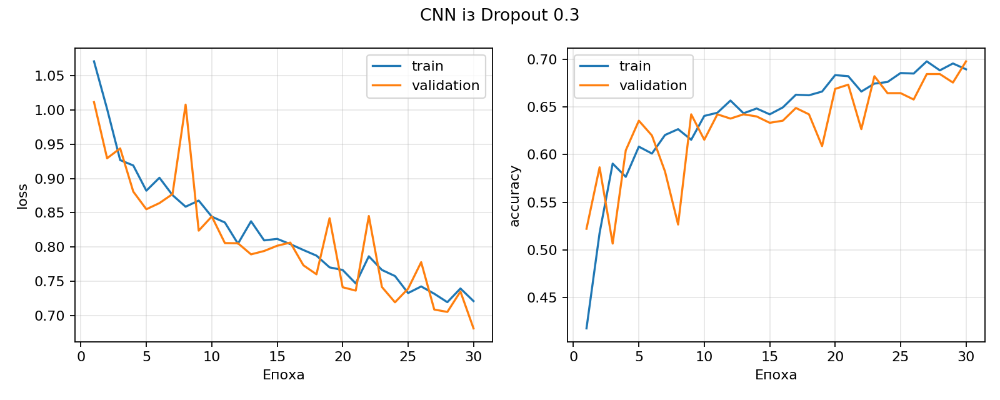

In [9]:
keras.utils.set_random_seed(SEED)
changed_model = make_model(dropout=0.3)
changed_history, changed_record = fit_model(changed_model, "dropout_03")
plot_history(changed_history, "CNN із Dropout 0.3", "dropout_curves.png")
comparison = pd.DataFrame([base_record, changed_record]).set_index("model")
comparison.to_csv(RESULTS / "validation_comparison.csv")
display(comparison)
selected_name = "dropout_03" if changed_record["val_loss"] < base_record["val_loss"] else "baseline"
selected_model = changed_model if selected_name == "dropout_03" else model
selected_history = changed_history if selected_name == "dropout_03" else base_history
print("Обрано за validation loss:", selected_name)

## Крок 10. Незалежний test та метрики

Лише після вибору конфігурації відкриваємо офіційний test. Обчислюємо accuracy, precision, recall, F1 для кожного класу й macro-F1. Найчастіший train-клас у збалансованому наборі дає test accuracy `1/3`; випадкове рівномірне вгадування також має очікування `1/3`. Подальше налаштування за цим test порушило б його незалежність.

Found 750 files belonging to 3 classes.
Test loss/accuracy: {'accuracy': 0.7506666779518127, 'loss': 0.6170101165771484}
              precision    recall  f1-score     support
cheese_plate   0.763780  0.776000  0.769841  250.000000
garlic_bread   0.685106  0.644000  0.663918  250.000000
pizza          0.796935  0.832000  0.814090  250.000000
accuracy       0.750667  0.750667  0.750667    0.750667
macro avg      0.748607  0.750667  0.749283  750.000000
weighted avg   0.748607  0.750667  0.749283  750.000000
Найчастіший клас train на test: 0.3333333333333333 | macro-F1 моделі: 0.7492829383946459


Lab9.ipynb cell 21:29: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


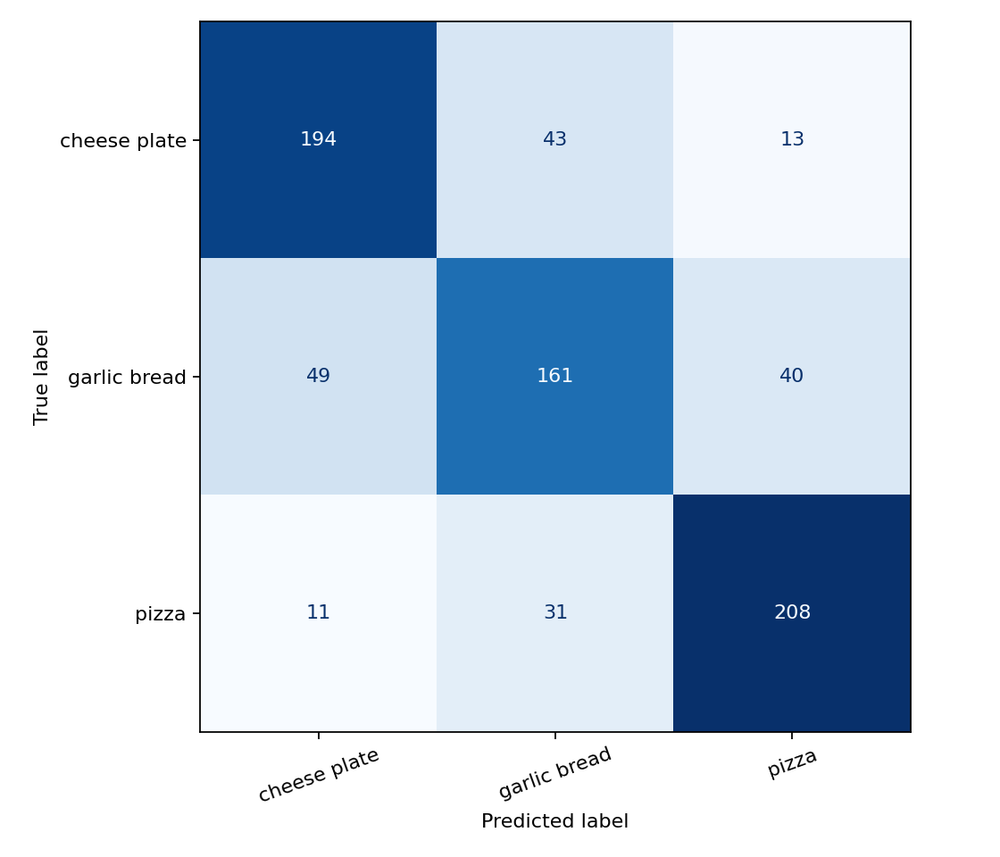

In [10]:
test_ds = load_split("test")
test_metrics = selected_model.evaluate(test_ds, verbose=0, return_dict=True)
y_true = np.concatenate([y.numpy() for _, y in test_ds])
probabilities = selected_model.predict(test_ds, verbose=0)
y_pred = probabilities.argmax(axis=1)
assert len(y_true) == len(y_pred) == 750
report = classification_report(y_true, y_pred, labels=[0, 1, 2],
                               target_names=CLASS_NAMES, zero_division=0, output_dict=True)
report_df = pd.DataFrame(report).T
report_df.to_csv(RESULTS / "test_classification_report.csv")
print("Test loss/accuracy:", test_metrics)
display(report_df)
train_counts = Counter(x.split("/", 1)[0] for x in split_ids["train"])
majority_label = CLASS_NAMES.index(max(CLASS_NAMES, key=lambda x: train_counts[x]))
baseline_accuracy = accuracy_score(y_true, np.full_like(y_true, majority_label))
print("Найчастіший клас train на test:", baseline_accuracy,
      "| macro-F1 моделі:", f1_score(y_true, y_pred, average="macro"))
summary = {"selected_model": selected_name, "test_loss": float(test_metrics["loss"]),
           "test_accuracy": float(test_metrics["accuracy"]),
           "macro_f1": float(report["macro avg"]["f1-score"]),
           "majority_accuracy": float(baseline_accuracy)}
(RESULTS / "test_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, labels=[0, 1, 2],
    display_labels=[x.replace("_", " ") for x in CLASS_NAMES], ax=ax,
    xticks_rotation=20, cmap="Blues", colorbar=False)
fig.tight_layout()
fig.savefig(RESULTS / "confusion_matrix.png", dpi=160)
plt.show()

## Крок 11. Приклади прогнозів і помилок

Показуємо шість прогнозів та до шести помилок з істинним класом, передбаченим класом і найбільшою softmax-оцінкою. Softmax-оцінка не гарантує правильності. При огляді помилок перевірте схожість страв, фон, ракурс, обрізання та можливий шум міток.

Помилок: 187 із 750


Lab9.ipynb cell 23:18: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


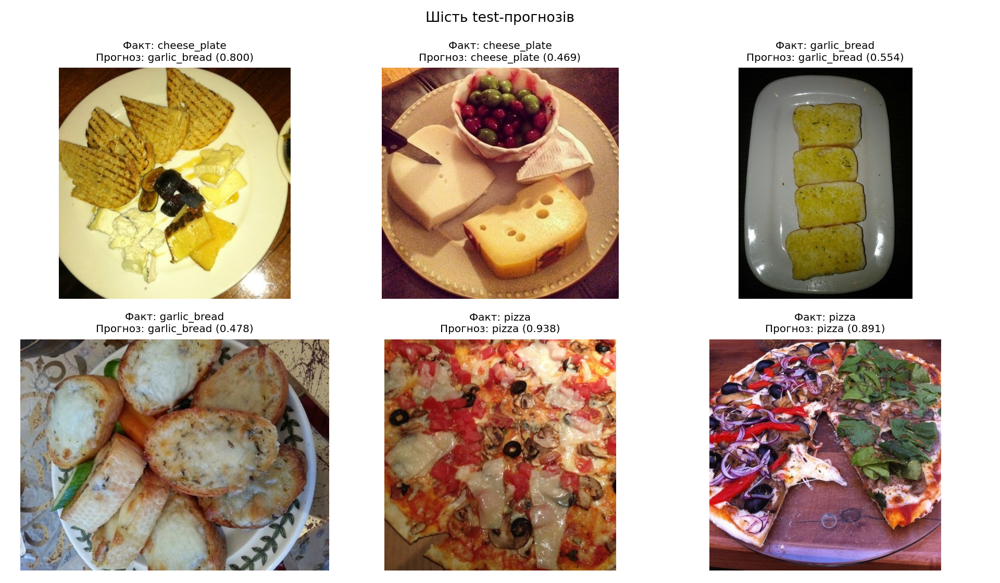

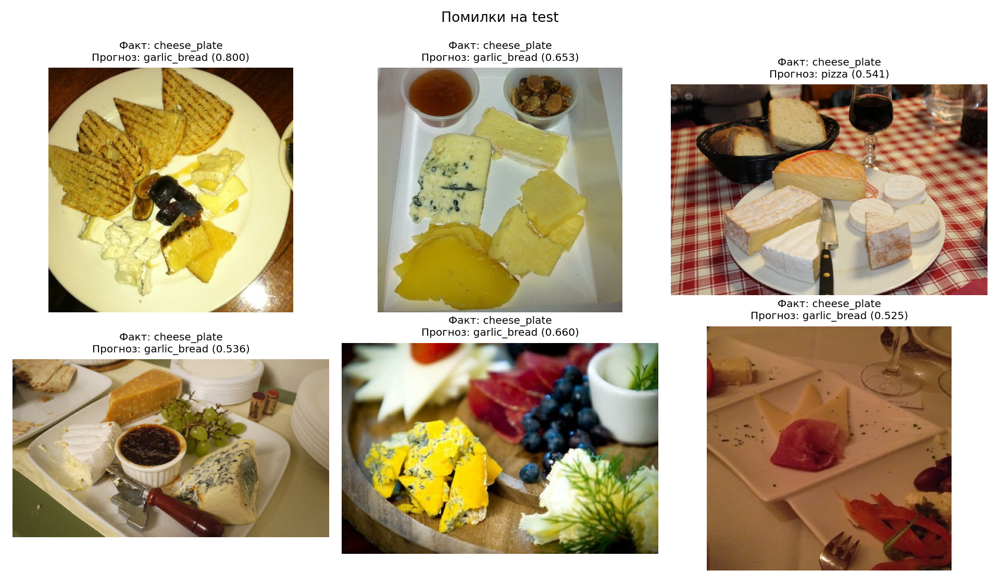

In [11]:
test_files = [p for name in CLASS_NAMES for p in sorted((DATA_ROOT / "test" / name).glob("*.jpg"))]
assert len(test_files) == len(y_true)

def show_predictions(indices, title, filename):
    if len(indices) == 0:
        print(title + ": немає прикладів")
        return
    fig, axes = plt.subplots(2, 3, figsize=(12, 7))
    for ax in axes.flat:
        ax.axis("off")
    for ax, idx in zip(axes.flat, indices):
        with Image.open(test_files[idx]) as im:
            ax.imshow(im.convert("RGB"))
        ax.set_title(f"Факт: {CLASS_NAMES[y_true[idx]]}\nПрогноз: {CLASS_NAMES[y_pred[idx]]} ({probabilities[idx].max():.3f})", fontsize=9)
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(RESULTS / filename, dpi=160)
    plt.show()

sample_idx = np.linspace(0, len(y_true)-1, 6, dtype=int)
show_predictions(sample_idx, "Шість test-прогнозів", "predictions.png")
error_idx = np.flatnonzero(y_true != y_pred)
show_predictions(error_idx[:6], "Помилки на test", "errors.png")
print("Помилок:", len(error_idx), "із", len(y_true))

## Крок 12. Карти ознак та зовнішнє фото

Перший Conv має 16 вихідних карт `(128,128)`. Показуємо чотири активації **конкретного входу після ReLU**, а не ваги фільтра. Кожну карту відображено зі спільною шкалою кольору, тому значення можна порівнювати між картами. Для окремого прогнозу використовується зовнішнє фото піци з Wikimedia Commons, яке не входить до Food-101. Джерело: [PizzaMargherita.jpg](https://commons.wikimedia.org/wiki/File:PizzaMargherita.jpg), автор SIG SG 510, ліцензія CC0 1.0. Це демонстрація на новому фото, не власний знімок студента. Вхід лишається у шкалі 0–255, бо Rescaling уже в моделі. Мережа не має класу «невідомо».

Прогноз: pizza | softmax: {'cheese_plate': 0.014700000174343586, 'garlic_bread': 0.302700012922287, 'pizza': 0.6826000213623047}
Зовнішнє фото показано на графіку.


<string>:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
<string>:35: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


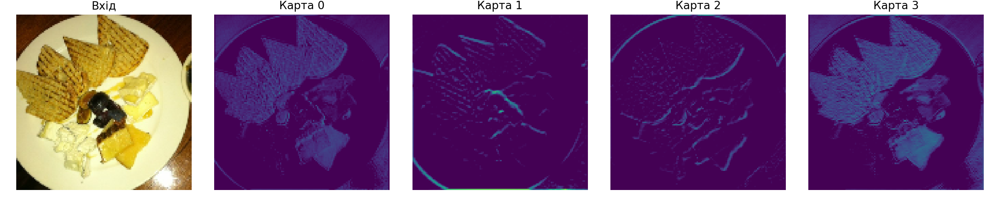

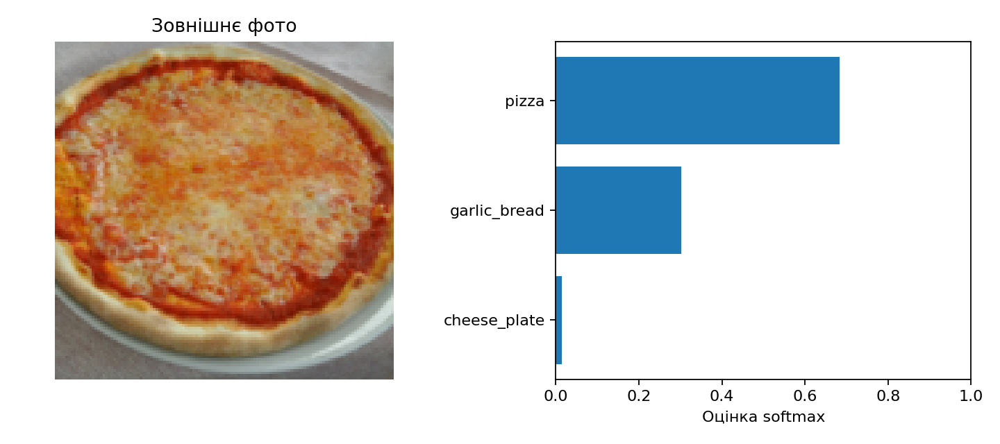

In [12]:
feature_model = keras.Model(selected_model.inputs, selected_model.get_layer("conv1").output)
example, _ = next(iter(test_ds))
feature_maps = feature_model(example[:1], training=False).numpy()
assert feature_maps.shape == (1, 128, 128, 16)
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
axes[0].imshow(example[0].numpy().astype(np.uint8)); axes[0].set_title("Вхід")
for i in range(4):
    axes[i+1].imshow(feature_maps[0, :, :, i], cmap="viridis", vmin=0,
                     vmax=float(feature_maps[0].max()))
    axes[i+1].set_title(f"Карта {i}")
for ax in axes: ax.axis("off")
fig.tight_layout(); fig.savefig(RESULTS / "feature_maps.png", dpi=160); plt.show()

OWN_PHOTO = RESULTS / "external_pizza.jpg"  # Зовнішнє фото, не частина Food-101
if OWN_PHOTO is None:
    print("Власне фото ще не задане: укажіть OWN_PHOTO і повторно виконайте цю клітинку.")
else:
    photo_path = Path(OWN_PHOTO).expanduser()
    assert photo_path.is_file(), photo_path
    own_img = keras.utils.load_img(photo_path, target_size=IMAGE_SIZE, interpolation="bilinear")
    own_array = keras.utils.img_to_array(own_img)[None, ...]
    own_probs = selected_model.predict(own_array, verbose=0)[0]
    print("Прогноз:", CLASS_NAMES[int(np.argmax(own_probs))],
          "| softmax:", dict(zip(CLASS_NAMES, own_probs.round(4).tolist())))
    external_result = {"source": "https://commons.wikimedia.org/wiki/File:PizzaMargherita.jpg",
                       "author": "SIG SG 510", "license": "CC0 1.0",
                       "expected_class": "pizza",
                       "predicted_class": CLASS_NAMES[int(np.argmax(own_probs))],
                       "probabilities": dict(zip(CLASS_NAMES, own_probs.tolist()))}
    (RESULTS / "external_prediction.json").write_text(json.dumps(external_result, ensure_ascii=False, indent=2), encoding="utf-8")
    fig, axes = plt.subplots(1, 2, figsize=(9, 4))
    axes[0].imshow(own_img); axes[0].axis("off"); axes[0].set_title("Зовнішнє фото")
    axes[1].barh(CLASS_NAMES, own_probs)
    axes[1].set_xlim(0, 1); axes[1].set_xlabel("Оцінка softmax")
    fig.tight_layout(); fig.savefig(RESULTS / "external_prediction.png", dpi=160); plt.show()
    display(own_img)

## Крок 13. Збереження моделі й висновки

Зберігаємо модель разом із шаром `Rescaling`; окремо — порядок класів і параметри передобробки. Висновок нижче друкує **фактичні** validation/test-значення після запуску. На одному поділі й одному seed перевага моделі може бути випадковою; наступний обґрунтований крок — повторити експеримент з кількома seed або перевірити підозрілі мітки, не використовуючи test для вибору.

### Фактичний висновок цього запуску

Базова CNN і модель із Dropout пройшли по 30 епох; найкраща епоха для обох — 30-та. Dropout зменшив validation loss з **0,6878** до **0,6813**, але validation accuracy змінилася з **0,7089** до **0,6978**. За наперед заданим правилом мінімального validation loss обрано Dropout. Різниця loss лише **0,0065**, тому одного seed недостатньо, щоб стверджувати про стійку перевагу.

На незалежному test обрана модель отримала **accuracy 0,7507**, **macro-F1 0,7493** проти **0,3333** accuracy простого класифікатора більшості. Recall: `cheese_plate` — **0,776**, `garlic_bread` — **0,644**, `pizza` — **0,832**. Найбільше помилок припадає на `garlic_bread`: 49 фото віднесено до `cheese_plate`, 40 — до `pizza`. Із `cheese_plate` 43 фото віднесено до `garlic_bread`; в одному показаному кадрі сухарики займають значну частину тарілки з сиром. Плутанині можуть сприяти спільні текстури хліба й сирних закусок, фон, масштаб і ракурс. Це пояснення за візуальним оглядом, а не доведена причина кожної помилки.

Обидві криві loss загалом спадали до 30-ї епохи; явного стійкого зростання validation loss немає. Тому наступний дослід — повторити запуск із кількома seed або обережно збільшити верхню межу епох **за validation**, не використовуючи test для нового вибору. Для окремої демонстрації використано зовнішнє CC0-фото піци з Wikimedia Commons; воно не є власним знімком студента. Модель передбачила `pizza` з softmax-оцінкою **0,6826** (інші оцінки: `garlic_bread` — 0,3027, `cheese_plate` — 0,0147).

In [13]:
selected_model.save(LAB_DIR / "food_cnn.keras")
(LAB_DIR / "class_names.json").write_text(json.dumps(CLASS_NAMES, ensure_ascii=False, indent=2), encoding="utf-8")
preprocessing = {"image_size": IMAGE_SIZE, "color_mode": "rgb", "interpolation": "bilinear",
                 "pixel_range": "0..255", "rescaling_in_model": "1/255",
                 "class_names": CLASS_NAMES, "seed": SEED}
(RESULTS / "preprocessing.json").write_text(json.dumps(preprocessing, ensure_ascii=False, indent=2), encoding="utf-8")

first = comparison.loc["baseline"]
second = comparison.loc["dropout_03"]
change = "зменшився" if second.val_loss < first.val_loss else "не зменшився"
best = int(np.argmin(selected_history.history["val_loss"]))
train_loss_at_best = selected_history.history["loss"][best]
val_loss_at_best = selected_history.history["val_loss"][best]
gap = val_loss_at_best - train_loss_at_best
print(f"Висновок. Dropout 0.3: validation loss {first.val_loss:.4f} → {second.val_loss:.4f} ({change}); "
      f"validation accuracy {first.val_accuracy:.3f} → {second.val_accuracy:.3f}. "
      f"За мінімальним validation loss обрано {selected_name}; test accuracy={summary['test_accuracy']:.3f}, "
      f"macro-F1={summary['macro_f1']:.3f} проти accuracy більшості={baseline_accuracy:.3f}. "
      f"На найкращій епосі train loss={train_loss_at_best:.4f}, val loss={val_loss_at_best:.4f}, "
      f"розрив val−train={gap:+.4f}. Матриця помилок і фото вище показують конкретні типи плутанини. "
      "Обмеження: один поділ, один seed, шум train-міток і можливе спотворення пропорцій після resize. "
      "Наступний крок: повторити досліди з кількома seed та переглянути підозрілі мітки.")

Висновок. Dropout 0.3: validation loss 0.6878 → 0.6813 (зменшився); validation accuracy 0.709 → 0.698. За мінімальним validation loss обрано dropout_03; test accuracy=0.751, macro-F1=0.749 проти accuracy більшості=0.333. На найкращій епосі train loss=0.7211, val loss=0.6813, розрив val−train=-0.0398. Матриця помилок і фото вище показують конкретні типи плутанини. Обмеження: один поділ, один seed, шум train-міток і можливе спотворення пропорцій після resize. Наступний крок: повторити досліди з кількома seed та переглянути підозрілі мітки.
